# Mini Project — Rebuild Your RAG with LangChain
### IT7075: Applied AI for Cybersecurity · Dharmin Patel

The RAG module built retrieval by hand. This notebook builds the same system with LangChain, on the
same documents and the same eight questions, and then compares the two.

| | You write | Replaces (from `rag_notebook.ipynb`) |
|---|---|---|
| **TODO 1** | load the file and split it | `split_into_chunks()` + `load_and_chunk()` |
| **TODO 2** | build the vector store | `embed()` + `build_collection()` / `collection.add()` |
| **TODO 3** | make a retriever with `k` and a score threshold | `retrieve()` |
| **TODO 4** | write the prompt template | `SYSTEM` string + `build_context()` |
| **TODO 5** | wire the chain with the pipe operator | `ask()` + `generate()` |

Parts 1–7 are practice on the course documents (`../rag_project/course_kb/`). From **Part 8** on, the RAG is rebuilt on
my own incident-response knowledge base (`my_kb/`, `goldset.json`), unchanged from the RAG module.

> **Runs offline** on CPU with `all-MiniLM-L6-v2`. If `OPENAI_API_KEY` is set in `.env` (never in this
> notebook), the last stage of the chain uses `gpt-4o-mini`; otherwise an offline stand-in quotes the context.

## Part 1 — Load and split  ·  **TODO 1**

`TextLoader` reads a file into a `Document` (text + `metadata["source"]`). A text splitter cuts documents
into overlapping chunks and copies the metadata onto every chunk, so the source file travels with each chunk
without any bookkeeping on my side.

In [1]:
# pip install langchain-core langchain-community langchain-text-splitters langchain-chroma langchain-huggingface langchain-openai
import os, json, hashlib, logging
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")      # CPU only, as in the RAG module
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# an empty retrieval is the expected result for a refusal; silence LangChain's log line about it
logging.getLogger("langchain_core.vectorstores.base").setLevel(logging.ERROR)

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter, CharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnablePassthrough, RunnableParallel, RunnableBranch

load_dotenv(); load_dotenv("../.env")

def first_existing(*paths):
    for p in paths:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(paths[0])

COURSE_KB = [first_existing("course_kb/" + n, "../rag_project/course_kb/" + n) for n in ("ssrf.txt", "cybersecurity_kb.md")]
BASELINE_GOLD = first_existing("baseline_goldset.json", "../rag_project/baseline_goldset.json")


###################  TODO 1 — load the file and split it  ###################
# Replaces split_into_chunks() and load_and_chunk() from the RAG module.
################
def load_and_split(files, chunk_size=600, overlap=100, splitter_cls=RecursiveCharacterTextSplitter):
    docs = [d for path in files for d in TextLoader(path, encoding="utf-8").load()]
    splitter = splitter_cls(chunk_size=chunk_size, chunk_overlap=overlap)
    return splitter.split_documents(docs)


course_chunks = load_and_split(COURSE_KB)
for path in COURSE_KB:
    print("  %-24s -> %2d chunks" % (os.path.basename(path), sum(c.metadata["source"] == path for c in course_chunks)))
print("  TOTAL:", len(course_chunks), "chunks")
print("\nFirst chunk:", course_chunks[0].metadata, "\n", course_chunks[0].page_content[:70])

/var/folders/7l/1nqyd35n1fz_hqtbtbkhszyh0000gn/T/ipykernel_83007/2110214874.py:13: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


  ssrf.txt                 -> 13 chunks
  cybersecurity_kb.md      -> 10 chunks
  TOTAL: 23 chunks

First chunk: {'source': '../rag_project/course_kb/ssrf.txt'} 
 Server-Side Request Forgery Prevention Cheat Sheet
Introduction
The ob


## Part 2 — Build the vector store  ·  **TODO 2**

`HuggingFaceEmbeddings` wraps the same `all-MiniLM-L6-v2` model the RAG module used, and `Chroma.from_documents`
embeds every chunk and stores it in one call. The collection is still set to **cosine** space: Chroma's
default is L2, and every threshold here assumes cosine.

In [2]:
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2",
                                   encode_kwargs={"normalize_embeddings": True})
_counter = [0]

###################  TODO 2 — build the vector store  ###################
# Replaces embed() + build_collection() / collection.add(ids=..., embeddings=..., metadatas=...).
################
def build_store(chunks):
    _counter[0] += 1                        # fresh collection each call, so re-runs never mix
    return Chroma.from_documents(chunks, embeddings,
                                 collection_name="kb_%d" % _counter[0],
                                 collection_metadata={"hnsw:space": "cosine"})


course_store = build_store(course_chunks)
print("Stored", course_store._collection.count(), "chunks")

/Users/dharminpatel/IT 7075C - APPLIED AI FOR CYBERSECURITY/rag_project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9242.71it/s]

Stored 23 chunks


## Part 3 — Retriever with `k` and a score threshold  ·  **TODO 3**

The RAG module kept hits **below** a maximum *distance*. LangChain keeps hits **above** a `score_threshold`,
a *relevance* score where higher means more similar. For a cosine collection LangChain computes
`relevance = 1 − distance`, so the RAG module's `max_distance = 0.75` is `score_threshold = 0.25` here.
The cell checks that conversion rather than trusting it.

In [3]:
###################  TODO 3 — make a retriever  ###################
# Replaces retrieve(collection, question, k, max_distance).
# Opposite direction: keep relevance >= score_threshold  (== distance <= 1 - score_threshold)
################
def make_retriever(store, k=4, score_threshold=0.25):
    return store.as_retriever(search_type="similarity_score_threshold",
                              search_kwargs={"k": k, "score_threshold": score_threshold})


course_retriever = make_retriever(course_store)
for q in ["Is SSRF limited to HTTP, or can other protocols be involved?", "What is the capital of France?"]:
    hits = course_retriever.invoke(q)
    print("Q:", q, "\n   hits kept by the retriever:", len(hits))
    # the retriever hides scores, so ask the store directly for the top 4 to see why
    for (doc, rel), (_, dist) in zip(course_store.similarity_search_with_relevance_scores(q, k=4),
                                     course_store.similarity_search_with_score(q, k=4)):
        print("     relevance %.3f  (distance %.3f)  %s  [%s]  %s..." % (
            rel, dist, "kept   " if rel >= 0.25 else "dropped", os.path.basename(doc.metadata["source"]),
            doc.page_content[:45].replace("\n", " ")))
        assert abs(rel - (1 - dist)) < 1e-6
    print()

Q: Is SSRF limited to HTTP, or can other protocols be involved? 
   hits kept by the retriever: 4
     relevance 0.790  (distance 0.210)  kept     [ssrf.txt]  SSRF is not limited to the HTTP protocol. Gen...
     relevance 0.676  (distance 0.324)  kept     [ssrf.txt]  Example Take the example of a web application...
     relevance 0.653  (distance 0.347)  kept     [ssrf.txt]  Cases Depending on the application’s function...
     relevance 0.584  (distance 0.416)  kept     [ssrf.txt]  Context SSRF is an attack vector that abuses ...

Q: What is the capital of France? 
   hits kept by the retriever: 0
     relevance 0.070  (distance 0.930)  dropped  [ssrf.txt]  The request sent to the internal application ...
     relevance 0.062  (distance 0.938)  dropped  [cybersecurity_kb.md]  # Network Security Fundamentals Network secur...
     relevance 0.051  (distance 0.949)  dropped  [ssrf.txt]  Application can send requests only to identif...
     relevance 0.040  (distance 0.960)  dropped  [cy

## Part 4 — Prompt template  ·  **TODO 4**

The prompt is a template with two placeholders, `{context}` and `{question}`, filled in at run time. The same
instructions as the RAG module's `SYSTEM` string: answer only from context, cite the file, refuse otherwise.

In [4]:
###################  TODO 4 — write the prompt template  ###################
# Replaces the SYSTEM string + SYSTEM.format(context=...) + build_context().
################
prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a cybersecurity assistant. Answer the question using ONLY the context below.\n"
     "Cite the source file for every claim, like [03_phishing_playbook.md]. If the answer is in the context, "
     "start your reply with [RAG]. If the context is empty or does not contain the answer, say you do not "
     "know and start with [LLM] -- do not answer from memory.\n\n# Context\n{context}"),
    ("human", "{question}"),
])

def format_docs(docs):
    # build_context(): numbered blocks with their source file; "" when nothing was retrieved
    return "\n\n".join("[%d] (source: %s)\n%s" % (i, os.path.basename(d.metadata["source"]), d.page_content)
                       for i, d in enumerate(docs, start=1))

print(prompt.invoke({"context": "[1] (source: demo.md)\nSome text.", "question": "A question?"}).to_string())

System: You are a cybersecurity assistant. Answer the question using ONLY the context below.
Cite the source file for every claim, like [03_phishing_playbook.md]. If the answer is in the context, start your reply with [RAG]. If the context is empty or does not contain the answer, say you do not know and start with [LLM] -- do not answer from memory.

# Context
[1] (source: demo.md)
Some text.
Human: A question?


## Part 5 — Wire the chain  ·  **TODO 5**

`retriever → format_docs` fills `{context}` while the question passes straight through to `{question}`; then
`prompt | model | parser`. The model is `gpt-4o-mini` when a key is present, with the offline stand-in as a
**fallback**, so a missing or expired key never breaks the notebook.

In [5]:
def offline_model(prompt_value):
    # stand-in for the LLM, same behaviour as generate() offline mode in the RAG module
    context = prompt_value.to_messages()[0].content.split("# Context\n", 1)[-1].strip()
    if not context:
        return "[LLM] I don't know -- the documents do not cover this. (offline mode)"
    return "[RAG] (offline mode) From the retrieved context:\n" + context[:300]

model = RunnableLambda(offline_model)
if os.getenv("OPENAI_API_KEY"):
    from langchain_openai import ChatOpenAI
    model = ChatOpenAI(model="gpt-4o-mini", temperature=0).with_fallbacks([model])
print("model:", type(model).__name__)

###################  TODO 5 — wire the chain with the pipe operator  ###################
# Replaces ask(): retrieve -> build_context -> SYSTEM.format -> generate.
################
def make_chain(retriever):
    return ({"context": retriever | format_docs, "question": RunnablePassthrough()}
            | prompt | model | StrOutputParser())


course_chain = make_chain(course_retriever)
for q in ["What are the two basic cases in which SSRF can happen?", "What CVSS score did Log4Shell receive?"]:
    print("Q:", q, "\n   ", course_chain.invoke(q)[:300].replace("\n", "\n    "), "\n")

model: RunnableLambda
Q: What are the two basic cases in which SSRF can happen? 
    [RAG] (offline mode) From the retrieved context:
    [1] (source: ssrf.txt)
    Cases
    Depending on the application’s functionality and requirements, there are two basic cases in which SSRF can happen:
    
    [2] (source: ssrf.txt)
    SSRF is not limited to the HTTP protocol. Generally, the first request is HTTP, but 

Q: What CVSS score did Log4Shell receive? 
    [LLM] I don't know -- the documents do not cover this. (offline mode) 



## Part 6 — Measure the practice pipeline

The same two counts as the RAG module: **found** (an answerable question retrieved a chunk containing its
evidence phrase) and **refused** (an unanswerable question retrieved nothing). Only the retriever is scored, so
the numbers do not depend on the LLM.

In [6]:
def found_evidence(docs, evidence):
    return any(p.lower() in d.page_content.lower() for d in docs for p in evidence)

def score(retriever, goldset):
    found = refused = 0
    for q in goldset:
        docs = retriever.invoke(q["question"])
        if q["answerable"]:
            found += found_evidence(docs, q["evidence"])
        else:
            refused += len(docs) == 0
    return found, refused

COURSE_GOLD = json.load(open(BASELINE_GOLD))["questions"]
f, r = score(course_retriever, COURSE_GOLD)
print("course documents, k=4, score_threshold=0.25 -> found %d/6, refused %d/2" % (f, r))

course documents, k=4, score_threshold=0.25 -> found 5/6, refused 2/2


## Part 7 — Parallel and branch

The dict at the start of the Part 5 chain is already a `RunnableParallel`: both keys get the same input and
run independently. A `RunnableBranch` instead runs **one** path chosen by a condition. Below, the branch
refuses without calling the model at all when retrieval came back empty, so the refusal no longer depends on
the model obeying the prompt. Part 9 uses this for my own bot.

In [7]:
def make_guarded_chain(retriever):
    answer = (RunnablePassthrough.assign(context=lambda x: format_docs(x["docs"]))
              | prompt | model | StrOutputParser())
    refuse = RunnableLambda(lambda x: "[REFUSED] Nothing in the knowledge base is relevant enough to answer.")
    route = RunnableBranch((lambda x: len(x["docs"]) == 0, refuse), answer)
    # parallel: fetch docs and keep the question; then branch; return answer AND sources
    return (RunnableParallel(docs=retriever, question=RunnablePassthrough())
            | RunnablePassthrough.assign(answer=route)
            | (lambda x: {"answer": x["answer"],
                          "sources": sorted({os.path.basename(d.metadata["source"]) for d in x["docs"]})}))

guarded = make_guarded_chain(course_retriever)
print(guarded.invoke("What CVSS score did Log4Shell receive?"))

{'answer': '[REFUSED] Nothing in the knowledge base is relevant enough to answer.', 'sources': []}


## Part 8 — My data: load and check

From here on, my own knowledge base. The documents and questions are copies of the RAG module's; the first cell
proves that by hashing them against `../rag_project/my_kb/` and `../rag_project/goldset.json`.

In [8]:
MY_FILES = sorted(str(p) for p in Path("my_kb").glob("*.md") if p.name != "SOURCES.md")
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()[:12]

print("Unchanged from the RAG module?")
for p in MY_FILES + ["goldset.json"]:
    orig = "../rag_project/" + p
    same = sha(p) == sha(orig) if os.path.exists(orig) else "n/a (original not found)"
    print("  %-34s %s  same: %s" % (p, sha(p), same))

docs_text = {os.path.basename(p): open(p, encoding="utf-8").read() for p in MY_FILES}
print("\n%d documents, %d characters" % (len(docs_text), sum(map(len, docs_text.values()))))

MY_GOLD = json.load(open("goldset.json"))["questions"]
n_ans = sum(q["answerable"] for q in MY_GOLD)
print("%d questions: %d answerable, %d unanswerable" % (len(MY_GOLD), n_ans, len(MY_GOLD) - n_ans))
for q in MY_GOLD:
    for phrase in q["evidence"]:
        assert phrase.lower() in docs_text[q["source"]].lower(), (q["qid"], phrase)
print("All evidence phrases found in the documents.")

Unchanged from the RAG module?
  my_kb/01_ir_overview.md            39c162869298  same: True
  my_kb/02_severity_levels.md        ea076a3660f1  same: True
  my_kb/03_phishing_playbook.md      b01c8382fb96  same: True
  my_kb/04_ransomware_playbook.md    6cd64da59d31  same: True
  my_kb/05_evidence_handling.md      1552a6c95383  same: True
  goldset.json                       0369dff40cd1  same: True

5 documents, 10104 characters
8 questions: 6 answerable, 2 unanswerable
All evidence phrases found in the documents.


## Part 9 — My RAG, rebuilt with LangChain

Same settings as the RAG module baseline: chunk 600 / overlap 100, k = 4, max distance 0.75 → **score threshold
0.25**. The bot is the guarded chain from Part 7. The transcript covers all eight questions, including the two it
should refuse.

In [9]:
BASE = dict(chunk_size=600, overlap=100, k=4, score_threshold=0.25)   # = RAG module baseline

my_chunks = load_and_split(MY_FILES, BASE["chunk_size"], BASE["overlap"])
my_store = build_store(my_chunks)
my_retriever = make_retriever(my_store, BASE["k"], BASE["score_threshold"])
my_bot = make_guarded_chain(my_retriever)
print("%d chunks stored (RecursiveCharacterTextSplitter)\n" % len(my_chunks))

print("=" * 30, "TRANSCRIPT", "=" * 30, "\n")
for q in MY_GOLD:
    out = my_bot.invoke(q["question"])
    print("[%s] %s\nQ: %s\n   sources: %s\n   answer: %s\n" % (
        q["qid"], "answerable" if q["answerable"] else "SHOULD REFUSE", q["question"],
        out["sources"] or "-", out["answer"][:300].replace("\n", "\n           ")))

25 chunks stored (RecursiveCharacterTextSplitter)

============================== TRANSCRIPT ============================== 



[Q1] answerable
Q: Who has the authority to declare a security incident closed?
   sources: ['01_ir_overview.md', '02_severity_levels.md']
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: 01_ir_overview.md)
           The Incident Commander is the only person who can declare an incident closed.
           
           ## Phase summary
           
           [2] (source: 01_ir_overview.md)
           ## Roles on the response team
           
           - **Incident Commander (IC):** owns the incident from decla

[Q2] answerable
Q: How quickly do we have to acknowledge a critical SEV1 incident?
   sources: ['02_severity_levels.md']
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: 02_severity_levels.md)
           - Acknowledge within 15 minutes, at any hour.
           - Page the Incident Commander, the CISO, and the on-call forensics lead.
           - Status updates to leadership every 60 minutes.
           - Legal i

### Per question: where the nearest chunk sits

In [10]:
def per_question(store, retriever, goldset):
    rows = []
    for q in goldset:
        docs = retriever.invoke(q["question"])
        top, rel = store.similarity_search_with_relevance_scores(q["question"], k=1)[0]
        rows.append({"qid": q["qid"], "answerable": q["answerable"], "hits": len(docs),
                     "nearest_relevance": round(rel, 3), "nearest_distance": round(1 - rel, 3),
                     "nearest_source": os.path.basename(top.metadata["source"]),
                     "correct": found_evidence(docs, q["evidence"]) if q["answerable"] else len(docs) == 0})
    return pd.DataFrame(rows)

f, r = score(my_retriever, MY_GOLD)
print("Baseline %s -> found %d/6, refused %d/2\n" % (BASE, f, r))
pq = per_question(my_store, my_retriever, MY_GOLD)
pq

Baseline {'chunk_size': 600, 'overlap': 100, 'k': 4, 'score_threshold': 0.25} -> found 5/6, refused 1/2



,qid,answerable,hits,nearest_relevance,nearest_distance,nearest_source,correct
0,Q1,True,4,0.629,0.371,01_ir_overview.md,True
1,Q2,True,4,0.673,0.327,02_severity_levels.md,True
2,Q3,True,4,0.490,0.510,03_phishing_playbook.md,False
3,Q4,True,4,0.699,0.301,04_ransomware_playbook.md,True
4,Q5,True,4,0.664,0.336,05_evidence_handling.md,True
5,Q6,True,4,0.696,0.304,05_evidence_handling.md,True
6,Q7,False,0,0.081,0.919,04_ransomware_playbook.md,True
7,Q8,False,4,0.488,0.512,03_phishing_playbook.md,False


## Part 10 — Experiments → `results_langchain.csv`

One setting changes at a time; the others stay at the baseline. The threshold sweep uses exactly the RAG module's
distances, converted with `score_threshold = 1 − max_distance`. A fourth sweep swaps the **splitter** at baseline
settings: `CharacterTextSplitter(separator="")` cuts fixed 600-character windows like my hand-written
`split_into_chunks()`, while the default `RecursiveCharacterTextSplitter` prefers paragraph and line breaks.

In [11]:
MAX_DISTANCES = [0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 1.0]       # the RAG module's sweep
SWEEPS = {
    "chunk_size":      [150, 300, 450, 600, 900, 1200, 2000],
    "k":               [1, 2, 3, 4, 6, 8],
    "score_threshold": [round(1 - d, 2) for d in MAX_DISTANCES],
    "splitter":        ["recursive", "character"],
}
SPLITTERS = {"recursive": RecursiveCharacterTextSplitter,
             "character": lambda **kw: CharacterTextSplitter(separator="", **kw)}

stores = {}          # (chunk_size, overlap, splitter) -> (store, n_chunks), each embedded once
def store_for(chunk_size, overlap, splitter):
    key = (chunk_size, overlap, splitter)
    if key not in stores:
        ch = load_and_split(MY_FILES, chunk_size, overlap, SPLITTERS[splitter])
        stores[key] = (build_store(ch), len(ch))
    return stores[key]

rows = []
for setting, values in SWEEPS.items():
    for v in values:
        cfg = {**BASE, "splitter": "recursive", setting: v}
        cfg["overlap"] = min(BASE["overlap"], cfg["chunk_size"] // 4)        # same rule as the RAG module
        store, n_chunks = store_for(cfg["chunk_size"], cfg["overlap"], cfg["splitter"])
        f, r = score(make_retriever(store, cfg["k"], cfg["score_threshold"]), MY_GOLD)
        rows.append({"experiment": setting, "splitter": cfg["splitter"], "chunk_size": cfg["chunk_size"],
                     "overlap": cfg["overlap"], "k": cfg["k"], "score_threshold": cfg["score_threshold"],
                     "equiv_max_distance": round(1 - cfg["score_threshold"], 2), "n_chunks": n_chunks,
                     "found": f, "refused": r, "total_correct": f + r})

results = pd.DataFrame(rows)
results.to_csv("results_langchain.csv", index=False)
print("Saved results_langchain.csv (%d configurations)" % len(results))
results

Saved results_langchain.csv (25 configurations)


,experiment,splitter,chunk_size,overlap,k,score_threshold,equiv_max_distance,n_chunks,found,refused,total_correct
0,chunk_size,recursive,150,37,4,0.25,0.75,122,5,1,6
1,chunk_size,recursive,300,75,4,0.25,0.75,53,5,1,6
2,chunk_size,recursive,450,100,4,0.25,0.75,34,6,1,7
3,chunk_size,recursive,600,100,4,0.25,0.75,25,5,1,6
4,chunk_size,recursive,900,100,4,0.25,0.75,17,6,1,7
5,chunk_size,recursive,1200,100,4,0.25,0.75,11,6,1,7
6,chunk_size,recursive,2000,100,4,0.25,0.75,7,6,1,7
7,k,recursive,600,100,1,0.25,0.75,25,4,1,5
8,k,recursive,600,100,2,0.25,0.75,25,4,1,5
9,k,recursive,600,100,3,0.25,0.75,25,4,1,5


## Part 11 — Comparison with the RAG module

Each LangChain row is matched to the RAG module row with the same chunk size, overlap, k, and the equivalent
distance (`../rag_project/results.csv`). The baseline row is the like-for-like comparison.

In [12]:
rag = pd.read_csv("../rag_project/results.csv")          # the RAG module's results, unchanged
lc = results[results.experiment != "splitter"].replace({"experiment": {"score_threshold": "max_distance"}})
cmp = lc.merge(rag, left_on=["experiment", "chunk_size", "overlap", "k", "equiv_max_distance"],
               right_on=["experiment", "chunk_size", "overlap", "k", "max_distance"],
               how="left", suffixes=("_lc", "_rag"))
cols = ["experiment", "chunk_size", "k", "max_distance", "score_threshold",
        "n_chunks_rag", "n_chunks_lc", "found_rag", "found_lc", "refused_rag", "refused_lc"]
like = (cmp.chunk_size == 600) & (cmp.k == 4) & (cmp.score_threshold == 0.25)
print("LIKE-FOR-LIKE (600/100, k=4, max_distance 0.75 == score_threshold 0.25):")
print(cmp.loc[like, cols].head(1).to_string(index=False), "\n")
cmp[cols]

LIKE-FOR-LIKE (600/100, k=4, max_distance 0.75 == score_threshold 0.25):
experiment  chunk_size  k  max_distance  score_threshold  n_chunks_rag  n_chunks_lc  found_rag  found_lc  refused_rag  refused_lc
chunk_size         600  4          0.75             0.25            22           25          6         5            1           1 



,experiment,chunk_size,k,max_distance,score_threshold,n_chunks_rag,n_chunks_lc,found_rag,found_lc,refused_rag,refused_lc
0,chunk_size,150,4,0.75,0.25,92,122,5,5,1,1
1,chunk_size,300,4,0.75,0.25,48,53,5,5,1,1
2,chunk_size,450,4,0.75,0.25,31,34,5,6,1,1
3,chunk_size,600,4,0.75,0.25,22,25,6,5,1,1
4,chunk_size,900,4,0.75,0.25,15,17,6,6,1,1
5,chunk_size,1200,4,0.75,0.25,11,11,6,6,1,1
6,chunk_size,2000,4,0.75,0.25,8,7,6,6,1,1
7,k,600,1,0.75,0.25,22,25,3,4,1,1
8,k,600,2,0.75,0.25,22,25,5,4,1,1
9,k,600,3,0.75,0.25,22,25,6,4,1,1


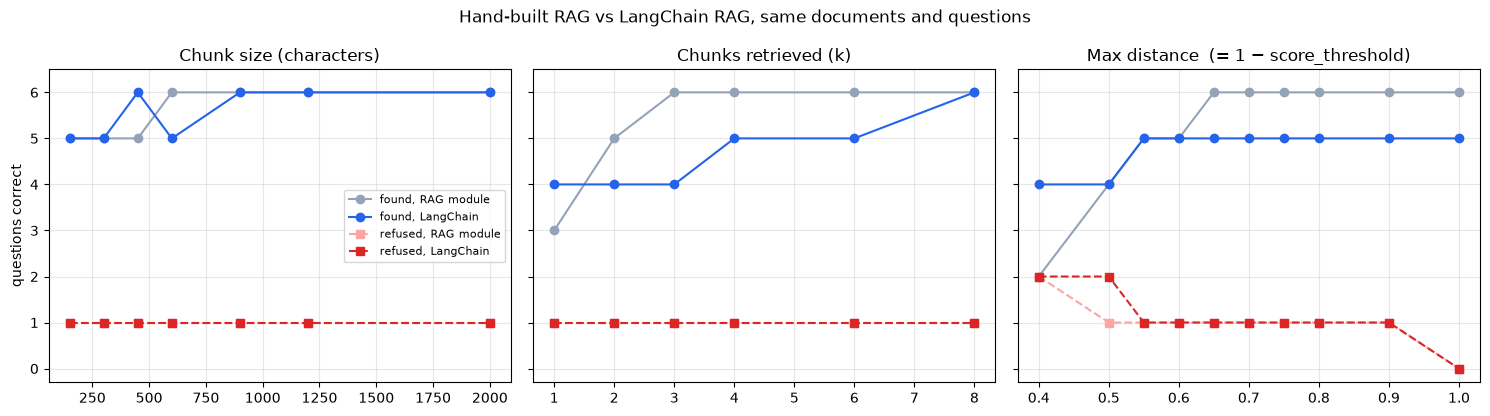

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (exp, xcol, title) in zip(axes, [("chunk_size", "chunk_size", "Chunk size (characters)"),
                                         ("k", "k", "Chunks retrieved (k)"),
                                         ("max_distance", "max_distance", "Max distance  (= 1 − score_threshold)")]):
    d = cmp[cmp.experiment == exp].sort_values(xcol)
    ax.plot(d[xcol], d.found_rag, "o-", color="#94a3b8", label="found, RAG module")
    ax.plot(d[xcol], d.found_lc, "o-", color="#2563eb", label="found, LangChain")
    ax.plot(d[xcol], d.refused_rag, "s--", color="#fca5a5", label="refused, RAG module")
    ax.plot(d[xcol], d.refused_lc, "s--", color="#dc2626", label="refused, LangChain")
    ax.set_title(title); ax.set_ylim(-0.3, 6.5); ax.grid(alpha=0.3)
axes[0].set_ylabel("questions correct"); axes[0].legend(loc="center right", fontsize=8)
fig.suptitle("Hand-built RAG vs LangChain RAG, same documents and questions")
fig.tight_layout(); fig.savefig("figure_comparison.png", dpi=150); plt.show()

## Part 12 — The question this version got wrong

The cell below lists every question the baseline LangChain bot got wrong, and for each one prints what the
retriever returned, with relevance scores, next to the chunk that holds the evidence.

In [14]:
wrong = pq[~pq.correct].qid.tolist()
print("Wrong at baseline:", wrong, "\n")
for qid in wrong:
    q = next(q for q in MY_GOLD if q["qid"] == qid)
    print("=" * 90, "\n%s: %s\n   evidence: %s\n" % (qid, q["question"], q["evidence"] or "(none: should refuse)"))
    ranked = my_store.similarity_search_with_relevance_scores(q["question"], k=len(my_chunks))
    for rank, (d, rel) in enumerate(ranked, 1):
        has = found_evidence([d], q["evidence"])
        if rank <= BASE["k"] or has:
            print("rank %d  relevance %.3f  [%s]%s\n   %s\n" % (
                rank, rel, os.path.basename(d.metadata["source"]), "  <-- HAS EVIDENCE" if has else "",
                d.page_content[:220].replace("\n", "\n   ")))

Wrong at baseline: ['Q3', 'Q8'] 

Q3: A user typed their password into a phishing page. How far back should we review their sign-in logs?
   evidence: ['Review sign-in logs for the last 14 days']

rank 1  relevance 0.490  [03_phishing_playbook.md]
   ## Closure
   
   Send the reporting user a thank-you note, because positive feedback raises reporting
   rates. Add the indicators of compromise to the threat intelligence platform. A
   phishing incident can be closed once all cop

rank 2  relevance 0.429  [03_phishing_playbook.md]
   ## Containment
   
   - Purge all copies of the message from every mailbox with the mail admin console.
   - Block the sender domain and the URLs at the mail gateway and the web proxy.
   - If any user clicked the link, check the pr

rank 3  relevance 0.403  [03_phishing_playbook.md]
   # Playbook: Phishing Email
   
   ## Trigger
   
   This playbook starts when a user reports a suspicious email with the "Report Phish"
   button, or when the mail gateway f

Why did the evidence chunk rank so low? The cell below shows how each splitter cut the phishing playbook around
the evidence, and how relevant the evidence chunk is to the question under each.

In [15]:
q3 = next(q for q in MY_GOLD if q["qid"] == "Q3")
phrase = q3["evidence"][0].lower()
text = docs_text["03_phishing_playbook.md"]
for name in ["recursive", "character"]:
    pieces = SPLITTERS[name](chunk_size=600, chunk_overlap=100).split_text(text)
    i = next(i for i, c in enumerate(pieces) if phrase in c.lower())
    rel = dict((d.page_content, s) for d, s in
               store_for(600, 100, name)[0].similarity_search_with_relevance_scores(q3["question"], k=50))[pieces[i]]
    print("=" * 30, "%s splitter: evidence in chunk %d of %d, relevance %.3f" % (name, i, len(pieces), rel), "=" * 30)
    print("...end of the chunk before:\n   " + pieces[i - 1][-170:].replace("\n", "\n   "))
    print("start of the evidence chunk:\n   " + pieces[i][:260].replace("\n", "\n   "), "\n")

============================== recursive splitter: evidence in chunk 3 of 5, relevance 0.275 ==============================
...end of the chunk before:
   er the page loaded.
   
   ## If credentials were entered
   
   Treat any user who typed a password into the phishing page as a compromised account.
   The response is SEV2 at minimum.
start of the evidence chunk:
   1. Reset the user's password and revoke all active sessions and refresh tokens.
   2. Re-register the user's MFA device in person or over a verified video call.
   3. Review sign-in logs for the last 14 days for logins from new countries or devices.
   4. Check the mai 

============================== character splitter: evidence in chunk 2 of 4, relevance 0.483 ==============================
...end of the chunk before:
   e loaded.
   
   ## If credentials were entered
   
   Treat any user who typed a password into the phishing page as a compromised account.
   The response is SEV2 at minimum.
   
   1. Reset
start of

---
## Summary

The report (`report/report.pdf`) discusses these results: what each LangChain stage replaced, what the framework hid
(chunk boundaries and the score conversion), the like-for-like comparison, and the question this version got wrong.